# Improvement experiments: what limits the CNN-GRU?

**Goal of this notebook:** find out where the next improvements can come from, with short, controlled experiments, before spending time on a long training run.

The first iteration (`2_modeling.ipynb`) ended with the CNN-GRU (physics head) at test R² 0.44 for HLC, 0.47 for HLC_ext and only 0.14 / 0.11 for tau_b / tau_inf. Train and validation losses were close and flat at the end, so the model is not overfitting. Two explanations are possible:
1. **The model is too small or badly set up**: then a bigger model or other settings should help.
2. **The inputs do not contain more information**: then only a different way of presenting the data can help, and tuning is wasted time. The nearest-neighbour test in section 8 of [the EDA notebook](./1_eda.ipynb) already points this way.

The experiments below are designed to tell these apart.

**Scope**
- The model input stays **T_int(t) and U(t) only**. Any extra channel (dT/dt, d²T/dt², cumulative energy) is computed from these two signals **inside the model**, so the interface stays (T, U) -> 6 targets. The `solicitation` table is not used.
- The outputs stay the six targets, and the physics head is kept (sum rule and tau ordering by construction).
- The **test split is not used** in this notebook. All decisions are made on the validation split.

**Guidance from the reference paper** (SSRN 6928008): it uses a CNN-GRU, evaluates with RMSE and the 95th percentile of the absolute error, and its main idea is that the **heating signal decides how well HLC can be identified** (it optimizes the PRBS parameters). Section 9 checks this idea on our data.

**Protocol (same for every variant)**
- 200,000 training scenarios (the first 200k of the saved training split), 6 epochs, same `TrainConfig` otherwise (AdamW, one-cycle learning rate, batch 256).
- 3 seeds fixed in advance: **0, 1, 2**. A seed sets the initial weights and the batch order; the split and the scalers never change. Every run is kept, none is picked by its result.
- Metrics on the full validation split (150,000 scenarios), in physical units. Each variant is reported as mean ± std over the seeds.
- **Decision rule:** a change counts only if it moves the metric by more than about 2 pooled standard deviations of the seeds (|z| > 2 in the summary table). Smaller changes are noise.
- Scores are lower than in `2_modeling.ipynb` (less data, fewer epochs). Only the **differences** between variants matter here.

Each (variant, seed) result is saved in `reports/experiments/`, so re-running the notebook skips finished runs.

## 1. Setup and data

In [1]:
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from coenergy.data import SplitData, load_splits
from coenergy.experiments import heating_pattern, make_log_tau_loss, make_weighted_loss, run_variant, summarize
from coenergy.metrics import per_target_metrics
from coenergy.models import build_cnn_gru, derivative_std, second_derivative_std
from coenergy.preprocessing import Scalers
from coenergy.training import TrainConfig, predict

SEED = 67  # seed of the split and scalers, unchanged
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'quentin_house'
SPLIT_PATH = PROJECT_ROOT / 'data' / 'splits' / f'split_70_15_15_seed{SEED}.pt'
SCALER_PATH = PROJECT_ROOT / 'data' / 'splits' / f'scalers_seed{SEED}.pt'
RESULTS_DIR = PROJECT_ROOT / 'reports' / 'experiments'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
CKPT_DIR = PROJECT_ROOT / 'models'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Experiment budget, the same for every variant
N_SUB = 200_000
EPOCHS = 6
SEEDS = (0, 1, 2)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print(f'torch {torch.__version__} | device: {DEVICE}')

torch 2.11.0+cu128 | device: cuda


In [2]:
scalers = Scalers.load(SCALER_PATH)
data = load_splits(DATA_DIR, SPLIT_PATH, scalers)
train, val = data['train'], data['val']
del data  # the test split is not used in this notebook

dT_std = derivative_std(train.x)
d2T_std = second_derivative_std(train.x)
y_train_phys = scalers.denorm_targets(train.y)
labels = scalers.target_labels

cfg = TrainConfig(epochs=EPOCHS, max_train=N_SUB)
print(f'train {len(train):,} (experiments use the first {N_SUB:,}) | val {len(val):,}')
print(f'dT/dt scale {dT_std:.4f} | d2T/dt2 scale {d2T_std:.4f} (normalized units per minute)')
cfg

train 700,000 (experiments use the first 200,000) | val 150,000
dT/dt scale 0.0196 | d2T/dt2 scale 0.0110 (normalized units per minute)


TrainConfig(epochs=6, batch_size=256, lr=0.002, weight_decay=0.0001, patience=4, eval_batch_size=4096, max_train=200000, data_on_device=True, seed=67)

In [3]:
def make(extra=('dT',), width=64, gru_layers=2):
    # Builder for a fresh physics-head CNN-GRU; run_variant seeds the initial weights before calling it
    return lambda: build_cnn_gru(
        'physics', dT_std, scalers.tgt_mean, scalers.tgt_std, y_train_phys=y_train_phys,
        width=width, gru_layers=gru_layers, extra=extra, d2T_std=d2T_std,
    )


results = {}


def run(name, make_model, train_split=None, val_split=None, config=None, loss_fn=None):
    results[name] = run_variant(name, make_model, train_split or train, val_split or val, scalers,
                                config or cfg, SEEDS, DEVICE, RESULTS_DIR, loss_fn=loss_fn)
    return results[name][['seed', 'val_loss', 'R2_HLC', 'R2_HLC_ext', 'R2_tau_b', 'minutes']].round(4)

## 2. Reference

The same model as the first iteration from [the modeling notebook](./2_modeling.ipynb) (physics head, dT/dt channel, width 64, 2 GRU layers), trained with the experiment budget. The spread between the 3 seeds is the noise level every other variant is compared with.

In [4]:
run('reference', make())

,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7433,0.4099,0.4196,0.1157,1.2396
1,1,0.7452,0.4078,0.4151,0.1143,1.2197
2,2,0.7471,0.4074,0.4088,0.1124,1.2098


## 3. Is the model too small?

I double the width (64 -> 128) and add a third GRU layer. If the model is too small to use the information in the inputs, both the training and the validation loss should drop clearly.

In [5]:
run('bigger', make(width=128, gru_layers=3))

,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7395,0.4125,0.4255,0.1206,3.5827
1,1,0.7387,0.4128,0.4282,0.1211,3.5747
2,2,0.7390,0.4136,0.4262,0.1209,3.5740


## 4. Does more data help?

I train the reference model on 100k and 400k scenarios (the reference uses 200k), with the same number of epochs. If validation keeps improving with more data, the full 700k (and longer training) is worth it; if it flattens, the model is close to a plateau for these inputs.

In [6]:
display(run('data_100k', make(), config=replace(cfg, max_train=100_000)))
run('data_400k', make(), config=replace(cfg, max_train=400_000))

,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7781,0.3845,0.3277,0.0847,0.7339
1,1,0.7734,0.3873,0.3436,0.0877,0.7353
2,2,0.7772,0.3826,0.3356,0.0868,0.7347


,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7324,0.4209,0.4401,0.1258,2.1859
1,1,0.7331,0.4197,0.4387,0.1254,2.1827
2,2,0.7332,0.4194,0.4389,0.1256,2.1814


## 5. Does the 0.01 °C rounding hide information? (diagnostic)

The piece of code from the assessment rounds the temperature to 0.01 °C. The EDA showed that very similar curves (within 0.05 °C) can have very different targets, so information might sit in differences smaller than the rounding. This is just a diagnosis where I experiment with using the raw simulated temperature instead.

In [7]:
raw = load_splits(DATA_DIR, SPLIT_PATH, scalers, round_inputs=False)
train_raw = SplitData(x=raw['train'].x[:N_SUB].clone(), y=raw['train'].y[:N_SUB].clone(), idx=raw['train'].idx[:N_SUB].clone())
val_raw = raw['val']
del raw

# The scalers and the dT/dt scale stay the same, so only the rounding differs
print(f'mean |raw - rounded| temperature: {((train_raw.x[:, 0] - train.x[:N_SUB, 0]).abs().mean() * scalers.temp_std):.4f} degC')
run('unrounded', make(), train_split=train_raw, val_split=val_raw)

mean |raw - rounded| temperature: 0.0025 degC


,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7351,0.4174,0.4397,0.1246,1.2338
1,1,0.7375,0.4137,0.4335,0.1231,1.2307
2,2,0.7397,0.4129,0.4273,0.1204,1.2696


In [8]:
del train_raw, val_raw

## 6. Does presenting the data differently help?

I added two channels computed from the inputs inside the model, like dT/dt:
- **Cumulative energy** ∫U dt (as a fraction of the window, 0 to 1): the heat injected so far. From the heat balance C · dT/dt = P − HLC · ΔT, comparing injected energy with the temperature rise points at heat capacity and HLC.
- **d²T/dt²**: the curvature of the temperature, i.e. how fast the rise or fall slows down, which is where HLC acts.

In [9]:
display(run('energy', make(extra=('dT', 'energy'))))
display(run('d2T', make(extra=('dT', 'd2T'))))
run('energy_d2T', make(extra=('dT', 'd2T', 'energy')))

,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7408,0.4120,0.4249,0.1187,1.3096
1,1,0.7405,0.4117,0.4259,0.1188,1.2746
2,2,0.7427,0.4095,0.4209,0.1174,1.2782


,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7439,0.4089,0.4176,0.1154,1.2550
1,1,0.7447,0.4082,0.4158,0.1145,1.2514
2,2,0.7471,0.4075,0.4097,0.1112,1.2509


,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7408,0.4123,0.4241,0.1180,1.2530
1,1,0.7421,0.4107,0.4213,0.1171,1.2539
2,2,0.7412,0.4114,0.4234,0.1177,1.2565


## 7. Does a log scale help the time constants?

The time constants are right-skewed (see EDA). Here the training loss compares the three time constants in log space (each log-tau z-scored with its training mean and std); the HLC family is unchanged. The physics head guarantees positive taus, so the log is always defined. The validation loss in the summary stays the usual normalized MSE, so the comparison is fair.

In [10]:
run('log_tau', make(), loss_fn=make_log_tau_loss(scalers, y_train_phys, DEVICE))

,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7485,0.4088,0.4136,0.1079,1.2286
1,1,0.7496,0.4076,0.4131,0.1070,1.2267
2,2,0.7496,0.4084,0.4103,0.1061,1.2275


## 8. Can HLC_ext and tau_n be improved by focusing on them?

HLC_ext and tau_n are the two targets in between: learned, but far from perfect. Here their weight in the training loss is doubled (weights 1, 1, 2, 1, 2, 1 for HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf, rescaled to average 1 so the loss keeps the same scale). The network then spends more of its shared capacity on these two targets.

The question is whether this is a real gain or only a trade-off: if HLC_ext and tau_n improve but the other targets lose about as much, the weighting only moves the error around. The validation loss in the summary stays the unweighted normalized MSE, so the comparison with the reference is fair.

In [11]:
WEIGHTS = [1, 1, 2, 1, 2, 1]  # HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf
run('weighted_ext_tau_n', make(), loss_fn=make_weighted_loss(scalers, WEIGHTS, DEVICE))

weighted_ext_tau_n seed 0 | val loss 0.7420 | R2 HLC 0.411 | 1.2 min


weighted_ext_tau_n seed 1 | val loss 0.7433 | R2 HLC 0.409 | 1.2 min


weighted_ext_tau_n seed 2 | val loss 0.7434 | R2 HLC 0.409 | 1.2 min


,seed,val_loss,R2_HLC,R2_HLC_ext,R2_tau_b,minutes
0,0,0.7420,0.4107,0.4229,0.1171,1.2494
1,1,0.7433,0.4089,0.4202,0.1154,1.2065
2,2,0.7434,0.4093,0.4197,0.1158,1.2105


**Observations (weighted loss)**

- **The targeted gains are tiny.** HLC_ext gains +0.006 in R² (z = 1.6, below the noise threshold) and tau_n +0.003 (z = 2.5, just above it). In physical units this is 0.05 W/K on HLC_ext MAE and 0.002 h on tau_n MAE.
- **There is no trade-off either:** the other targets do not get worse. This fits the capacity test: the shared network is not short of room, so moving its attention around changes almost nothing.
- **Conclusion: weighting does not help these two targets.** Their limit is the information in the inputs (tau_n needs a long block followed by a relaxation; HLC_ext needs the boundary temperatures), not how the training effort is spread. The weights are not kept, which also keeps the loss simple to justify (all targets count equally).

## Summary of experiments 2-8

For each variant: mean and std over the 3 seeds, the change against the reference (`delta`), and `z` = change / pooled seed std. **|z| > 2 means the change is larger than run-to-run noise.** For the validation loss, lower is better; for R², higher is better.

In [12]:
all_results = pd.concat(results.values(), ignore_index=True)
all_results.to_csv(RESULTS_DIR / 'all_runs.csv', index=False)

cols = ['val_loss'] + [f'R2_{l}' for l in labels]
summary = summarize(all_results, 'reference', cols)
summary.to_csv(RESULTS_DIR / 'summary.csv')

# Compact view: mean ± std, and z against the reference
view = pd.DataFrame({
    col: [f"{summary.loc[v, (col, 'mean')]:.4f} ± {summary.loc[v, (col, 'std')]:.4f}" for v in summary.index]
    for col in cols
}, index=summary.index)
display(view)
print('z against the reference (|z| > 2 = real change):')
display(summary.xs('z', axis=1, level=1).round(1))
print('minutes per run (mean):')
display(all_results.groupby('variant', sort=False)[['minutes', 'params']].mean().round(1))

,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf
variant,,,,,,,
reference,0.7452 ± 0.0019,0.4084 ± 0.0014,0.2625 ± 0.0006,0.4145 ± 0.0054,0.1141 ± 0.0017,0.2397 ± 0.0014,0.0894 ± 0.0011
bigger,0.7391 ± 0.0004,0.4130 ± 0.0006,0.2665 ± 0.0003,0.4266 ± 0.0014,0.1209 ± 0.0003,0.2443 ± 0.0002,0.0940 ± 0.0003
data_100k,0.7762 ± 0.0025,0.3848 ± 0.0023,0.2492 ± 0.0020,0.3357 ± 0.0079,0.0864 ± 0.0015,0.2167 ± 0.0026,0.0698 ± 0.0012
data_400k,0.7329 ± 0.0005,0.4200 ± 0.0008,0.2697 ± 0.0005,0.4392 ± 0.0007,0.1256 ± 0.0002,0.2503 ± 0.0005,0.0974 ± 0.0001
unrounded,0.7374 ± 0.0023,0.4147 ± 0.0024,0.2642 ± 0.0007,0.4335 ± 0.0062,0.1227 ± 0.0021,0.2448 ± 0.0012,0.0952 ± 0.0013
energy,0.7413 ± 0.0012,0.4111 ± 0.0014,0.2640 ± 0.0008,0.4239 ± 0.0026,0.1183 ± 0.0008,0.2422 ± 0.0012,0.0923 ± 0.0005
d2T,0.7452 ± 0.0017,0.4082 ± 0.0007,0.2624 ± 0.0005,0.4144 ± 0.0041,0.1137 ± 0.0023,0.2404 ± 0.0010,0.0895 ± 0.0015
energy_d2T,0.7414 ± 0.0007,0.4115 ± 0.0008,0.2646 ± 0.0004,0.4230 ± 0.0015,0.1176 ± 0.0004,0.2428 ± 0.0007,0.0919 ± 0.0004
log_tau,0.7493 ± 0.0006,0.4083 ± 0.0006,0.2621 ± 0.0004,0.4124 ± 0.0018,0.1070 ± 0.0009,0.2356 ± 0.0011,0.0788 ± 0.0008


z against the reference (|z| > 2 = real change):


,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf
variant,,,,,,,
reference,0.0,0.0,0.0,0.0,0.0,0.0,0.0
bigger,-4.5,4.4,9.1,3.1,5.5,4.7,6.0
data_100k,14.0,-12.4,-9.3,-11.6,-17.1,-11.2,-17.6
data_400k,-8.9,10.3,13.5,6.4,9.5,10.1,10.7
unrounded,-3.7,3.2,2.7,3.3,4.5,3.9,4.8
energy,-2.4,2.0,2.2,2.2,3.2,2.0,3.5
d2T,0.0,-0.1,-0.2,-0.0,-0.2,0.5,0.1
energy_d2T,-2.7,2.7,4.1,2.1,2.8,2.8,3.2
log_tau,2.9,-0.1,-0.8,-0.5,-5.3,-3.3,-11.1


minutes per run (mean):


,minutes,params
variant,,
reference,1.2,246085.0
bigger,3.6,1205637.0
data_100k,0.7,246085.0
data_400k,2.2,246085.0
unrounded,1.2,246085.0
energy,1.3,246533.0
d2T,1.3,246533.0
energy_d2T,1.3,246981.0
log_tau,1.2,246085.0


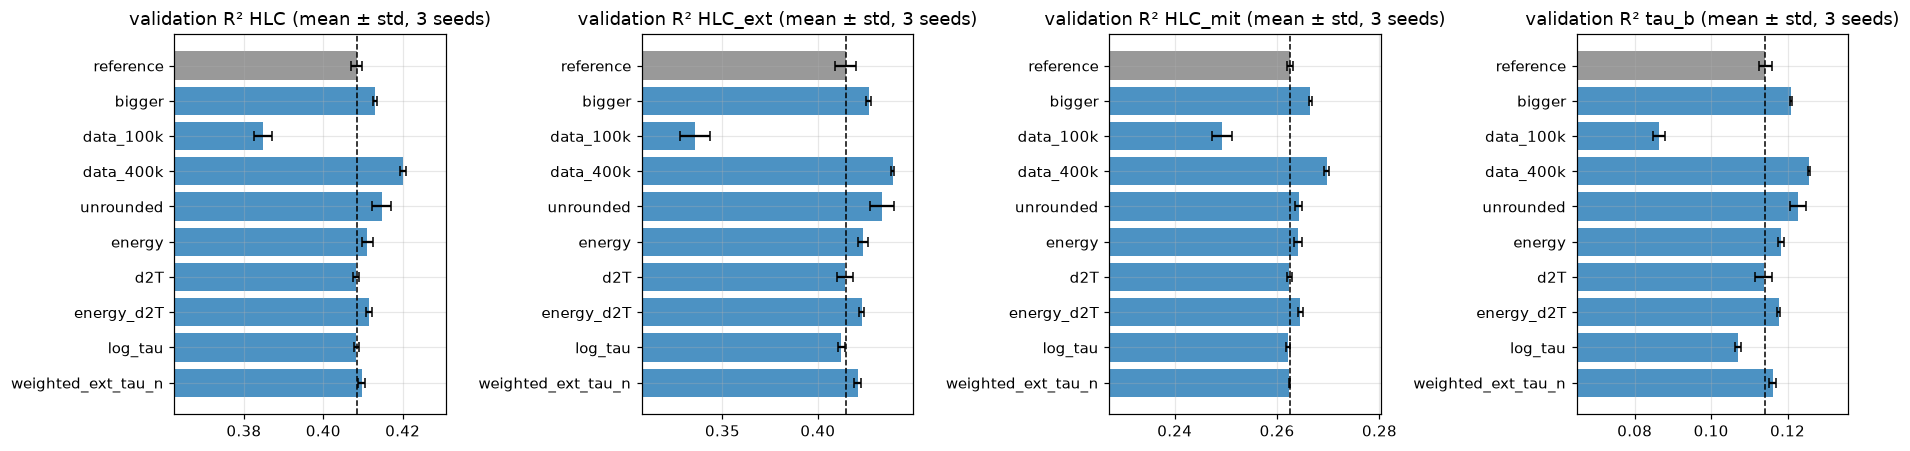

In [13]:
show = ['R2_HLC', 'R2_HLC_ext', 'R2_HLC_mit', 'R2_tau_b']
variants = list(summary.index)
fig, axes = plt.subplots(1, len(show), figsize=(17, 4.2), sharey=False)
for ax, col in zip(axes, show):
    m, s = summary[(col, 'mean')], summary[(col, 'std')]
    colors = ['gray' if v == 'reference' else 'tab:blue' for v in variants]
    ax.barh(variants, m, xerr=s, color=colors, alpha=0.8, capsize=3)
    ax.axvline(m['reference'], color='black', lw=1, ls='--')
    lo = (m - s).min()
    ax.set_xlim(lo - 0.02, (m + s).max() + 0.01)
    ax.set_title(col.replace('R2_', 'validation R² ') + ' (mean ± std, 3 seeds)')
    ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / 'experiments_r2.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations (experiments 2-8)**

The seed-to-seed noise is very small (std about 0.001-0.002 in R² for HLC), so even small changes can be measured. Changes against the reference (validation R², mean of 3 seeds):

| Variant | HLC | HLC_ext | tau_b | Val loss | Verdict |
|---|---|---|---|---|---|
| reference | 0.408 | 0.415 | 0.114 | 0.7452 | – |
| bigger (5× parameters) | +0.005 | +0.012 | +0.007 | 0.7391 | real but small, 3× slower |
| 100k scenarios | −0.024 | −0.079 | −0.028 | 0.7762 | less data hurts clearly |
| 400k scenarios | +0.012 | +0.025 | +0.012 | 0.7329 | more data helps the most |
| unrounded temperature | +0.006 | +0.019 | +0.009 | 0.7374 | real (diagnostic only) |
| + cumulative energy | +0.003 | +0.009 | +0.004 | 0.7413 | small, borderline real (z ≈ 2–3) |
| + d²T/dt² | 0.000 | 0.000 | 0.000 | 0.7452 | no effect |
| + energy + d²T | +0.003 | +0.009 | +0.004 | 0.7414 | same as energy alone |
| log-tau loss | 0.000 | −0.002 | −0.007 | 0.7493 | worse on the time constants |
| weights ×2 on HLC_ext, tau_n | +0.001 | +0.006 | +0.002 | 0.7429 | at noise level, no trade-off |

- **The model is not much too small.** Five times more parameters gives only +0.005 in HLC R², for three times the training time. The architecture is not the main limit.
- **More data still helps, with diminishing returns.** HLC R² goes 0.385 -> 0.408 -> 0.420 for 100k -> 200k -> 400k: each doubling adds less. The full model (700k, 20 epochs) reached 0.437, so training on everything already captures most of this.
- **The 0.01 °C rounding costs a little information** (+0.006 HLC, +0.019 HLC_ext without it). The rounding changes the temperature by only 0.0025 °C on average, yet it matters, which confirms that the model uses very small temperature differences (as the EDA's nearest-neighbour test suggested). For coEnergy this means sensor resolution matters. The final model keeps the rounding: the assessment's example loading code rounds the inputs on purpose (0.01 °C for T, 0.1 W for U), which looks like a sensor resolution, so I treat it as part of the input definition.
- **Cumulative energy gives a small but measurable gain on this subset**, mostly on HLC_ext and the time constants (on the full data it did not carry over, see the follow-up in section 10). **d²T/dt² adds nothing**: the convolutions already compute curvature from T and dT/dt.
- **The log-tau loss makes the time constants worse in R²**: it optimizes errors on a log scale, while R² and MAE are measured in hours, so it trades large-tau accuracy for small-tau accuracy. Rejected.
- **Overall: no change gives more than about +0.012 in HLC R².** This agrees with the data-ceiling picture: the limit is mainly what the inputs contain, not how the model processes them.

## 9. Does the heating signal decide the error? (the reference paper's idea)

The paper's main point is that the excitation signal controls how well HLC can be identified. Here the fully trained physics-head model from `2_modeling.ipynb` (`models/cnn_gru_physics.pt`, trained on all 700k scenarios for 20 epochs) is scored on the **validation** split, grouped by the number of heater switches in each scenario. The number of switches is read from U(t), the model's own input.

In [14]:
model = build_cnn_gru('physics', dT_std, scalers.tgt_mean, scalers.tgt_std, y_train_phys=y_train_phys)
model.load_state_dict(torch.load(CKPT_DIR / 'cnn_gru_physics.pt', weights_only=False)['state_dict'])
model.to(DEVICE)
pred_val = predict(model, val.x)
y_val = scalers.denorm_targets(val.y)

pattern = heating_pattern(val.x[:, 1])
bins = [-1, 0, 2, 5, 10, 20, 1000]
names = ['0 (constant)', '1-2', '3-5', '6-10', '11-20', '21+']
pattern['group'] = pd.cut(pattern['switches'], bins=bins, labels=names)

rows = []
for g in names:
    mask = torch.from_numpy((pattern['group'] == g).to_numpy().copy())
    m = per_target_metrics(pred_val[mask], y_val[mask], labels)
    rows.append({'switches': g, 'scenarios': int(mask.sum()), 'mean duty cycle': pattern.loc[mask.numpy(), 'duty_cycle'].mean(),
                 'HLC MAE (W/K)': m.loc['HLC', 'MAE'], 'HLC R2': m.loc['HLC', 'R2'],
                 'HLC_ext R2': m.loc['HLC_ext', 'R2'], 'tau_n R2': m.loc['tau_n', 'R2'], 'tau_b R2': m.loc['tau_b', 'R2']})
by_switches = pd.DataFrame(rows).set_index('switches')
overall = per_target_metrics(pred_val, y_val, labels)
print(f"all validation: HLC MAE {overall.loc['HLC', 'MAE']:.2f} W/K | HLC R2 {overall.loc['HLC', 'R2']:.3f}")
by_switches.round(3)

all validation: HLC MAE 18.75 W/K | HLC R2 0.437


,scenarios,mean duty cycle,HLC MAE (W/K),HLC R2,HLC_ext R2,tau_n R2,tau_b R2
switches,,,,,,,
0 (constant),13844,0.095,20.978001,0.305,0.502,0.256,0.194
1-2,91376,0.525,18.174999,0.469,0.513,0.284,0.147
3-5,23515,0.454,19.061001,0.428,0.439,0.237,0.131
6-10,9733,0.484,18.955000,0.423,0.373,0.230,0.090
11-20,3785,0.499,19.742001,0.385,0.257,0.208,0.048
21+,7747,0.510,19.924999,0.369,0.222,0.179,0.034


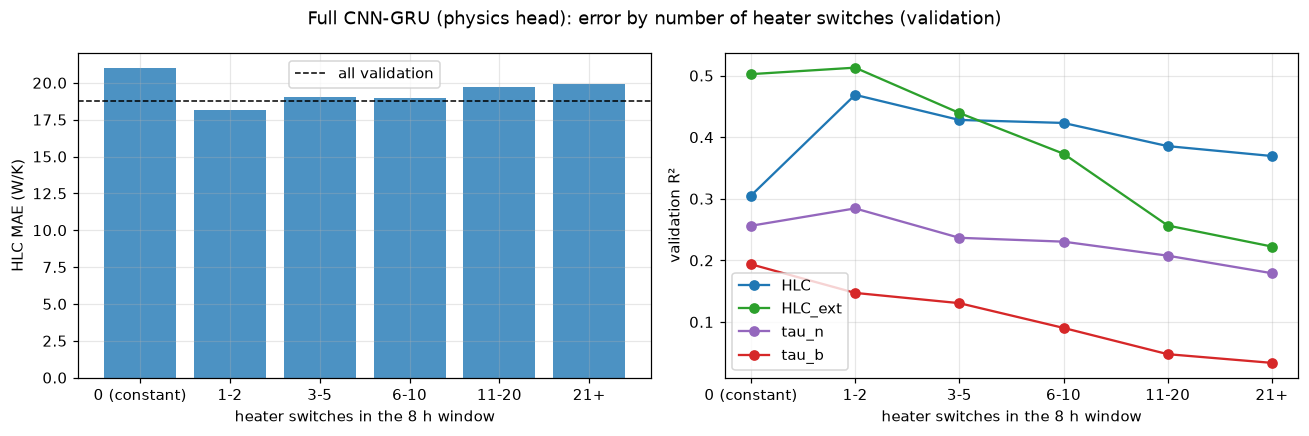

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(names))
axes[0].bar(x, by_switches['HLC MAE (W/K)'], color='tab:blue', alpha=0.8)
axes[0].axhline(overall.loc['HLC', 'MAE'], color='black', ls='--', lw=1, label='all validation')
axes[0].set_xticks(x, names); axes[0].set_xlabel('heater switches in the 8 h window'); axes[0].set_ylabel('HLC MAE (W/K)')
axes[0].legend()
for col, c in [('HLC R2', 'tab:blue'), ('HLC_ext R2', 'tab:green'), ('tau_n R2', 'tab:purple'), ('tau_b R2', 'tab:red')]:
    axes[1].plot(x, by_switches[col], marker='o', color=c, label=col.replace(' R2', ''))
axes[1].set_xticks(x, names); axes[1].set_xlabel('heater switches in the 8 h window'); axes[1].set_ylabel('validation R²')
axes[1].legend()
fig.suptitle('Full CNN-GRU (physics head): error by number of heater switches (validation)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'error_by_switches.png', dpi=150)
plt.show()

**Observations (heating signal)**
- **The error depends strongly on the heating pattern, and more switching is worse.** I expected the opposite at first (more switches = more events to learn from). Scenarios with 1-2 switches are predicted best (HLC R² 0.469, MAE 18.2 W/K); with 21 or more switches, HLC R² drops to 0.369 (MAE 19.9 W/K).
- **The time constants and HLC_ext show it most:** tau_b R² goes from 0.147 (1-2 switches) to 0.034 (21+), and HLC_ext from 0.513 to 0.222.
- The switching groups have the same average duty cycle (about 0.5), so the difference is not *how much* heating, but *how long each block lasts*. Many switches means short blocks (minutes): the air heats and cools quickly, but the walls stay near an average state, so the slow behaviour that sets HLC and the time constants is barely excited. Long blocks (hours) push the building toward a new level and let it relax, which reveals the steady-state gain (HLC) and the slow time constants.
- **Constant heating** (mostly never heated) is the worst for HLC (R² 0.305) but the best for tau_b (0.194): an 8-hour free drift says little about the heat loss, but it shows the slow relaxation of the walls.

## 10. Conclusions and next strategy

**What limits the model.** Not the architecture (5× parameters: +0.005 R²), not unstable training (the seeds agree within 0.002), and not the way the targets are scaled (log-tau is worse). The limit is mainly **the information in the inputs**: more data helps with diminishing returns, finer temperature resolution helps a little, and the heating pattern changes the error far more than any model change (HLC R² 0.37 to 0.47 between groups, against +0.012 at most for model changes).

**Decisions for the final model**
- To train on **all 700k** training scenarios for 20 epochs (the data experiment shows more data still helps).
- To keep the **physics head** and the **dT/dt** channel, and add the **cumulative-energy** channel (small but real gain here, almost free).
- To train **3 seeds** (0, 1, 2) and average their predictions. The seeds give error bars, and an average of physics-head models still respects the rules.
- To drop: the bigger model (3× slower for +0.005), d²T/dt² (no effect), the log-tau loss (worse) and the loss weights (noise level).
